<a href="https://colab.research.google.com/github/Manoja1912/AI-Trip-Planner/blob/main/ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

import zipfile
import io
import urllib.request

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

response = urllib.request.urlopen(url)
zip_data = zipfile.ZipFile(io.BytesIO(response.read()))

# Extract bank.zip from the main zip which contains the CSVs
inner_zip_bytes = zip_data.read("bank.zip")
inner_zip_data = zipfile.ZipFile(io.BytesIO(inner_zip_bytes))

# Load the bank-full.csv from the inner zip
df = pd.read_csv(inner_zip_data.open("bank-full.csv"), sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df

Dataset loaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
# Check missing values
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [ ]:
#Check duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
#Check the target column
print("Target value counts:")
print(df["y"].value_counts())

print("\nTarget percentages:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

Target value counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Target percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


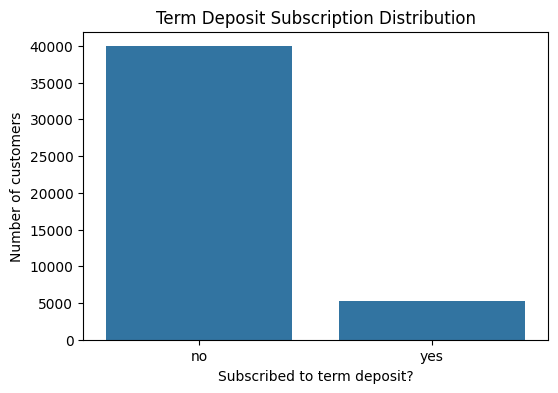

In [ ]:
#Visualize the target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="y")
plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscribed to term deposit?")
plt.ylabel("Number of customers")
plt.show()

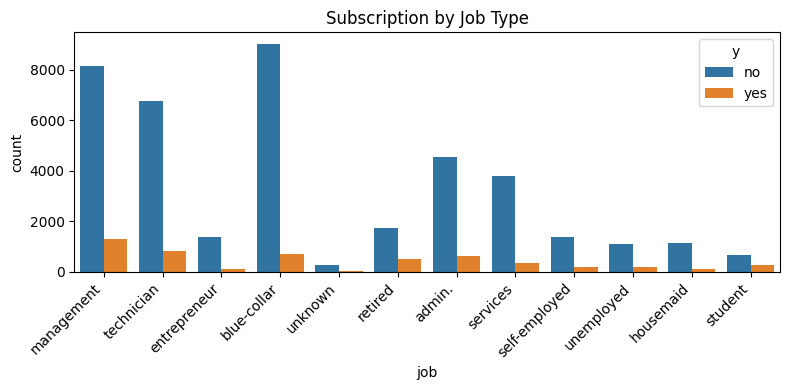

In [ ]:
#Explore selected features
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="job", hue="y")
plt.title("Subscription by Job Type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

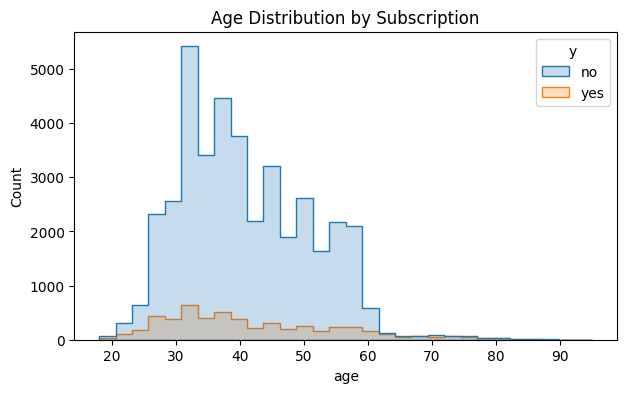

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="age", hue="y", bins=30, element="step", stat="count", common_norm=False)
plt.title("Age Distribution by Subscription")
plt.show()

In [ ]:
#Prepare features and target
# Separate input features (X) and target (y)
X = df.drop("y", axis=1)
y = df["y"].map({"no": 0, "yes": 1})

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (45211, 16)
Target shape: (45211,)


In [ ]:
#Identify numerical and categorical columns
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

print("Numerical columns:", num_cols)
print("\nCategorical columns:", cat_cols)

Numerical columns: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [ ]:
#Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 36168
Testing records: 9043


In [ ]:
#Preprocess the data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
#Train classification algorithms
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True, random_state=42),
    "MLP Neural Network": MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    print("Training:", name)
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    if hasattr(pipeline.named_steps["classifier"], "predict_proba"):
        y_prob = pipeline.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_prob)
    else:
        auc = np.nan

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": auc
    })
    trained_models[name] = pipeline

print("All models trained successfully!")

Training: Logistic Regression
Training: Decision Tree
Training: KNN
Training: SVM
Training: MLP Neural Network
All models trained successfully!


In [ ]:
#Compare model performance
results_df = pd.DataFrame(results).sort_values(by="F1 Score", ascending=False)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
4,MLP Neural Network,0.9050,0.6264,0.4660,0.5344,0.9187
1,Decision Tree,0.8998,0.6064,0.4093,0.4887,0.8423
3,SVM,0.9049,0.6875,0.3431,0.4578,0.9037
0,Logistic Regression,0.9012,0.6445,0.3478,0.4518,0.9056
2,KNN,0.8962,0.5990,0.3403,0.4340,0.8277


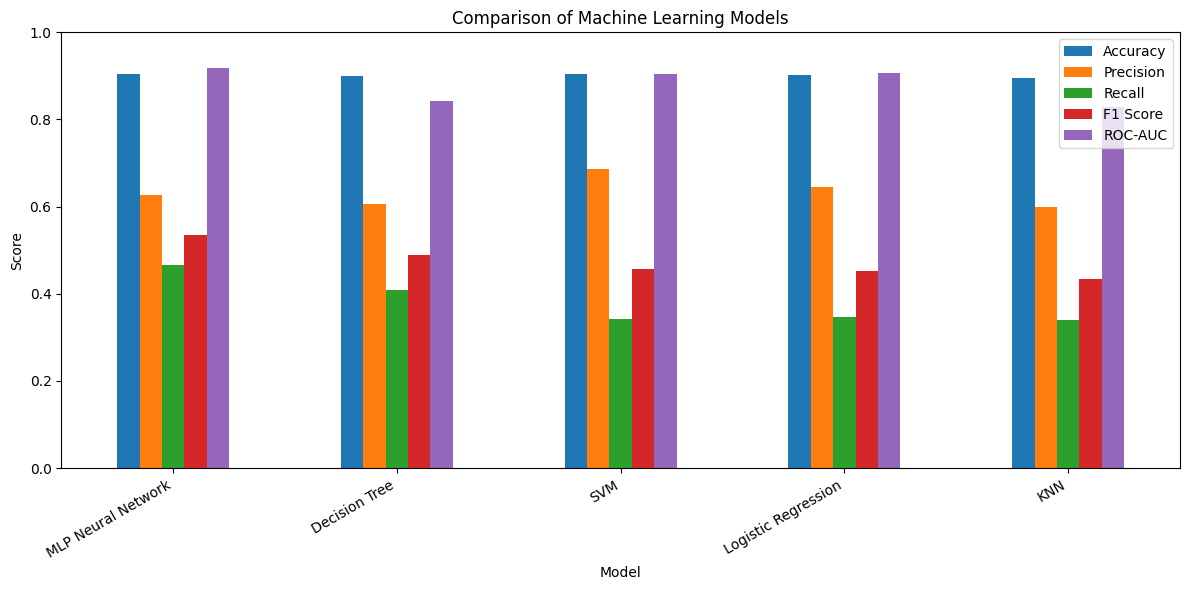

In [ ]:
#Visualize model comparison
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Best model by F1 score: MLP Neural Network

Classification report:
                 precision    recall  f1-score   support

No subscription       0.93      0.96      0.95      7985
   Subscription       0.63      0.47      0.53      1058

       accuracy                           0.91      9043
      macro avg       0.78      0.71      0.74      9043
   weighted avg       0.90      0.91      0.90      9043



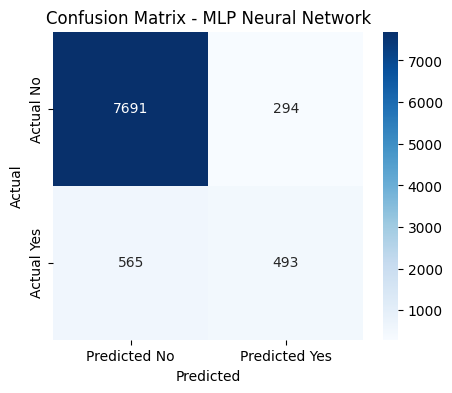

In [ ]:
#Confusion matrix for the best F1-score model
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_pred = best_model.predict(X_test)

print("Best model by F1 score:", best_model_name)
print("\nClassification report:")
print(classification_report(y_test, best_pred, target_names=["No subscription", "Subscription"]))

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted No", "Predicted Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.title("Confusion Matrix - " + best_model_name)
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

In [ ]:
#Conclusion
print("Project completed.")
print("Best model by F1 score:", best_model_name)
print("Review the comparison table and confusion matrix before writing your final conclusion.")
print("Note: because the target classes are imbalanced, do not judge the models using accuracy alone.")

Project completed.
Best model by F1 score: MLP Neural Network
Review the comparison table and confusion matrix before writing your final conclusion.
Note: because the target classes are imbalanced, do not judge the models using accuracy alone.
